# Subway incident and journey-performance relationships

## tl;dr
More weekday delay-causing incidents coincide with lower monthly customer journey-time performance. The line-and-month adjusted correlation is ?0.411 across 1,101 observed line-months. This is an association, not a causal effect.

## Context & Methods
The monthly view combines N and W as NW. Incidents cover whole weekdays; customer metrics cover weekdays 6 AM?11 PM. April 2025 S 42nd lacks an incident record and is excluded.

### Key Assumptions
Adjusted correlations use residuals after removing line and calendar-month averages by least-squares dummy regression. The lagged check includes only consecutive observed months. Incident counts are not normalized by service exposure.

## Data
Inputs are saved PostgreSQL query results in data/analysis/, generated by src/run_analysis.py and src/analyze_relationships.py.

In [1]:
from pathlib import Path
import pandas as pd, numpy as np, matplotlib.pyplot as plt, json, sys
from IPython.display import display
sys.path.insert(0,'src')
from analyze_relationships import residualized
DATA=Path('data/analysis')
plt.rcParams.update({'figure.figsize':(9,5),'font.size':10,'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.2})
monthly=pd.read_csv(DATA/'monthly_relationships.csv',parse_dates=['month'])
line_corr=pd.read_csv(DATA/'line_correlations.csv')
summary=json.loads((DATA/'relationship_summary.json').read_text())
valid=monthly.dropna(subset=['weekday_delay_incidents','cjt_percent']).copy()
print(len(valid),'observed line-months;',monthly.weekday_delay_incidents.isna().sum(),'missing incident row')

1101 observed line-months; 1 missing incident row


## Results
### Same-month adjusted association
Each dot is a line-month after removing average line and calendar-month differences. The fitted line is descriptive.

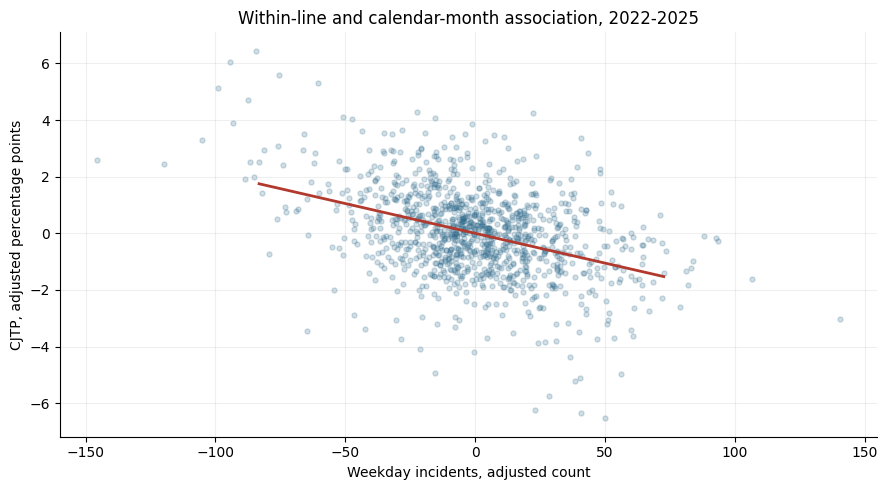

Pearson r: -0.411 Observations: 1101


In [2]:
x=residualized(valid,'weekday_delay_incidents',['line_id','month'])
y=residualized(valid,'cjt_percent',['line_id','month'])
fit=np.polyfit(x,y,1);xx=np.linspace(np.quantile(x,.01),np.quantile(x,.99),100)
fig,ax=plt.subplots();ax.scatter(x,y,s=13,alpha=.22,color='#306b8c');ax.plot(xx,np.polyval(fit,xx),color='#b2392d',linewidth=2)
ax.set(xlabel='Weekday incidents, adjusted count',ylabel='CJTP, adjusted percentage points',title='Within-line and calendar-month association, 2022-2025')
fig.tight_layout();plt.show()
print('Pearson r:',round(summary['incident_vs_cjt_line_and_month_adjusted'],3),'Observations:',summary['observations'])

### Association by comparison group
Bars are within-line monthly Pearson correlations; zero indicates no linear association.

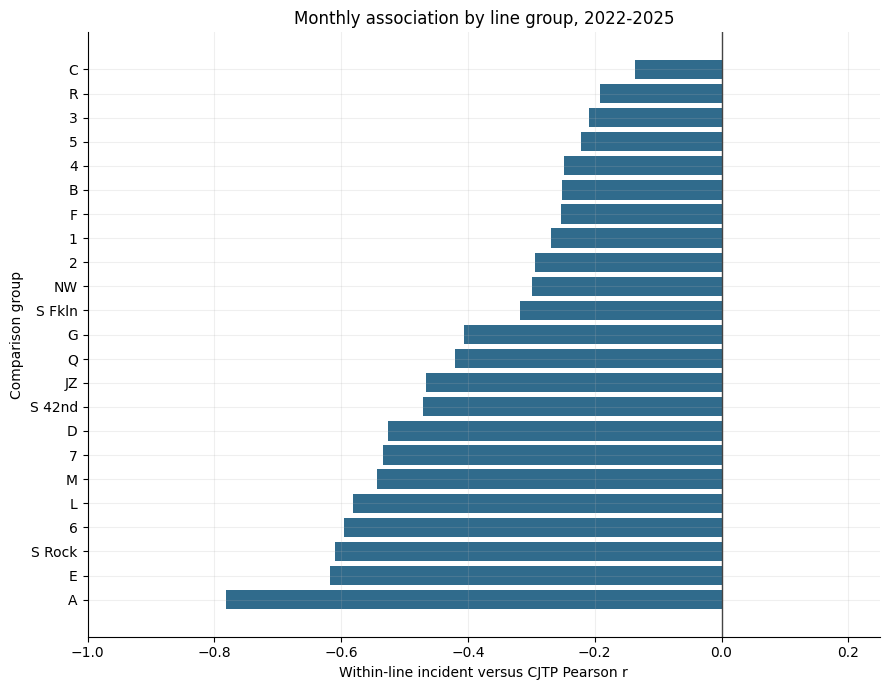

,line_id,months,incident_cjt_pearson
7,A,48.0,-0.782
11,E,48.0,-0.617
22,S Rock,48.0,-0.610
5,6,48.0,-0.596
15,L,48.0,-0.582
16,M,48.0,-0.544
6,7,48.0,-0.534
10,D,48.0,-0.527


In [3]:
ordered=line_corr.sort_values('incident_cjt_pearson')
fig,ax=plt.subplots(figsize=(9,7));ax.barh(ordered.line_id,ordered.incident_cjt_pearson,color='#306b8c');ax.axvline(0,color='#444444',linewidth=1)
ax.set(xlim=(-1,.25),xlabel='Within-line incident versus CJTP Pearson r',ylabel='Comparison group',title='Monthly association by line group, 2022-2025')
fig.tight_layout();plt.show()
display(ordered[['line_id','months','incident_cjt_pearson']].round(3).head(8))

### Lagged check
The next-month relationship is weaker. Lagging the monthly count does not establish an intervention effect.

In [4]:
display(pd.DataFrame([{'same_month_line_adjusted_r':summary['incident_vs_cjt_line_adjusted'],'next_month_line_adjusted_r':summary['incident_vs_next_month_cjt_line_adjusted'],'same_month_observations':summary['observations'],'lagged_observations':summary['lagged_observations']}]).round(3))

,same_month_line_adjusted_r,next_month_line_adjusted_r,same_month_observations,lagged_observations
0,-0.405,-0.291,1101,1077


### Incident-category associations
Each category is assessed separately after removing line and calendar-month averages. Categories overlap in time and attribution can change, so these coefficients do not rank causes.

In [5]:
categories=pd.read_csv(DATA/'category_associations.csv');display(categories.round(3))

,reporting_category,line_months,weekday_incidents,incident_cjt_line_and_month_adjusted_r
0,Infrastructure & Equipment,1101,50647,-0.276
1,Operating Conditions,1101,53567,-0.259
2,Police & Medical,1101,61494,-0.209
3,Planned ROW Work,1101,35445,-0.190
4,External Factors,1101,4546,-0.144
5,Crew Availability,1101,17577,-0.138


## Takeaways
The association can guide review of shared bad months, but monthly aggregates cannot identify causes or benefits from reducing a category. Review incident time, location, and operational logs for F, Q, B, and D before causal claims.